In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 06 — Improvement experiments, round 3 (runs 2 and 3)

Uses `train_lib_r3.py` and the round-3 data in `data_r3/` (8 validation regions). Earlier notebooks, data and runs are not changed.

Trains a list of experiments one after another and saves each to its own `runs/<RUN_NAME>/` folder.
Everything is shared through `train_lib_r3.py`, so results are directly comparable with 04a/b/c and with each other.
Compare everything afterwards in **05b_compare_r3.ipynb** (it finds new runs automatically).

| Run | Experiment | Change vs. 04a/b/c | Why |
|---|---|---|---|
| 2 | `A_unet_v2`, `B_deeplab_v2`, `C_segformer_v2` | 60 epochs, patience 12, **Lovász loss** instead of Dice | U-Net / DeepLabV3+ were still improving; Lovász optimises IoU directly |
| 3 | `C_segformer_v3` | v2 + LR 6e-5, 5 warm-up epochs, weight decay 0.01, stronger augmentation (±2 dB, month mixing) | SegFormer peaked at epoch 6 and overfitted |

**Rules**
* One change per experiment group, new `RUN_NAME` for every run — nothing is overwritten.
* Finished experiments are **skipped** when you re-run the notebook, unfinished ones **resume**. So if the session stops, just run all cells again.
* To test seed stability later, copy an entry, set `SEED = 7`, add `_s7` to `RUN_NAME` and keep the same `GROUP` — notebook 05b then reports mean ± std per group.

**Before running:** run `01b_download_r3.ipynb` and `02b_preprocessing_r3.ipynb` first (they create `data_r3/`).

## 1. Setup

In [1]:
import importlib, subprocess, sys
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q",
                           "--no-warn-script-location", "segmentation-models-pytorch"])
sys.path.append(".")
import gc, json, torch
from pathlib import Path
import train_lib_r3 as tl
from train_lib_r3 import DEV
print("torch", torch.__version__, "| device:", DEV)


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


torch 2.9.1+cu128 | device: cuda


## 2. Experiment list

`BASE` = the settings used in 04a/b/c. Each experiment only lists what it changes.
Comment out (`#`) any line you don't want to run now.

In [2]:
BASE = dict(
    DATA="data_r3", PRETRAINED=True, EPOCHS=40, WARMUP_EPOCHS=2, BATCH_SIZE=16, LR=3e-4,
    WEIGHT_DECAY=1e-4, PATIENCE=8, USE_CLASS_WEIGHTS=True, LOSS="dice", LABEL_SMOOTHING=0.0,
    NOISE_DB=1.0, MONTH_MIX=0.0, NUM_WORKERS=2, SEED=42,
)
LONGER_LOVASZ = dict(EPOCHS=60, PATIENCE=12, LOSS="lovasz")

EXPERIMENTS = [
    # ---- run 2: longer training + Lovász loss (all three models)
    dict(RUN_NAME="A_unet_v2",      GROUP="A_unet_v2",      ARCH="unet_resnet34",
         MODEL_NAME="U-Net / ResNet-34 v2",      **LONGER_LOVASZ),
    dict(RUN_NAME="B_deeplab_v2",   GROUP="B_deeplab_v2",   ARCH="deeplabv3plus_resnet50",
         MODEL_NAME="DeepLabV3+ / ResNet-50 v2", **LONGER_LOVASZ),
    dict(RUN_NAME="C_segformer_v2", GROUP="C_segformer_v2", ARCH="segformer_mitb2",
         MODEL_NAME="SegFormer / MiT-B2 v2",     **LONGER_LOVASZ, LR=1e-4),
    # ---- run 3: SegFormer-specific regularisation
    dict(RUN_NAME="C_segformer_v3", GROUP="C_segformer_v3", ARCH="segformer_mitb2",
         MODEL_NAME="SegFormer / MiT-B2 v3",     **LONGER_LOVASZ, LR=6e-5, WARMUP_EPOCHS=5,
         WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3),
]
for e in EXPERIMENTS:
    print(f"{e['RUN_NAME']:18s} {e['ARCH']:24s} " + ", ".join(f"{k}={v}" for k, v in e.items()
          if k not in ("RUN_NAME", "GROUP", "ARCH", "MODEL_NAME") and BASE.get(k) != v))

A_unet_v2          unet_resnet34            EPOCHS=60, PATIENCE=12, LOSS=lovasz
B_deeplab_v2       deeplabv3plus_resnet50   EPOCHS=60, PATIENCE=12, LOSS=lovasz
C_segformer_v2     segformer_mitb2          EPOCHS=60, PATIENCE=12, LOSS=lovasz, LR=0.0001
C_segformer_v3     segformer_mitb2          EPOCHS=60, PATIENCE=12, LOSS=lovasz, LR=6e-05, WARMUP_EPOCHS=5, WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3


## 3. Load the validation set once
(The same validation patches are used by every experiment.)

In [3]:
import shutil
_tmp, DATA, stats, index = tl.setup(dict(BASE, RUN_NAME="_tmp")); shutil.rmtree(_tmp)
val_ds = tl.EvalPatches(index[index.split == "val"].file, DATA, stats, "loading val")
print("val regions:", sorted(index[index.split == "val"].region.unique()))
print("train patches:", (index.split == "train").sum(), "| val patches:", (index.split == "val").sum())

device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB


loading val:   0%|          | 0/128 [00:00<?, ?it/s]

val regions: ['bangkok', 'danube_delta', 'iowa', 'las_vegas', 'madrid', 'saskatchewan', 'serengeti', 'sudd_wetland']
train patches: 700 | val patches: 128


## 4. Run all experiments
For each experiment: setup → data → model → sanity check → training → curves → validation results.


A_unet_v2  —  U-Net / ResNet-34 v2
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
train patches 700 | val samples 1536 (128 patches x 12 months)


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

24.4 M parameters | encoder weights: imagenet | loss: CE + lovasz
step  0  loss 3.160
step 10  loss 1.384
step 20  loss 0.992
step 29  loss 0.803


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 2.356 | val 2.430 | OA 0.516 | mIoU 0.243  *best* | 13s


... (114 outputs left out)

epoch 58:   0%|          | 0/43 [00:00<?, ?it/s]

ep 58 | train 0.792 | val 1.650 | OA 0.688 | mIoU 0.470 | 12s


epoch 59:   0%|          | 0/43 [00:00<?, ?it/s]

ep 59 | train 0.779 | val 1.631 | OA 0.692 | mIoU 0.474 | 12s
Done. Best val mIoU: 0.4878


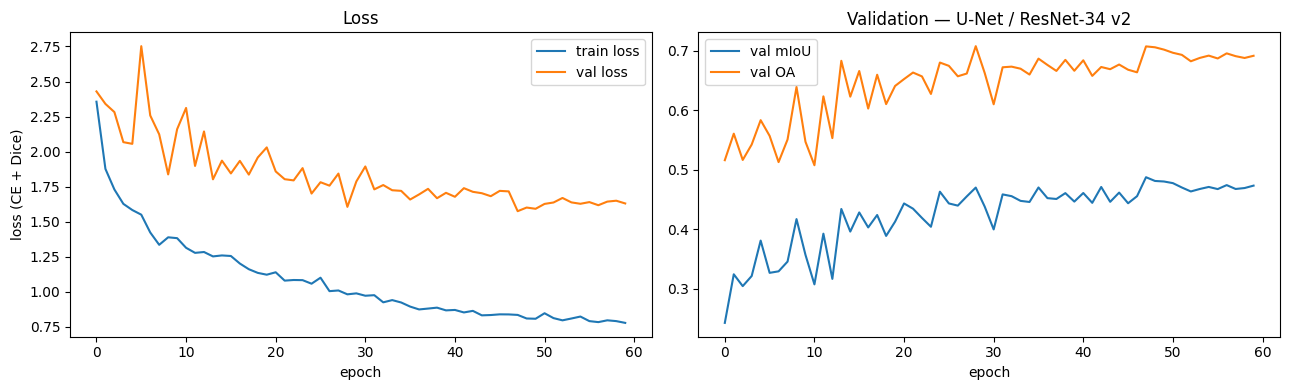

U-Net / ResNet-34 v2: val OA 0.708 | val mIoU 0.488 | 24.4 M params | 12.1 min


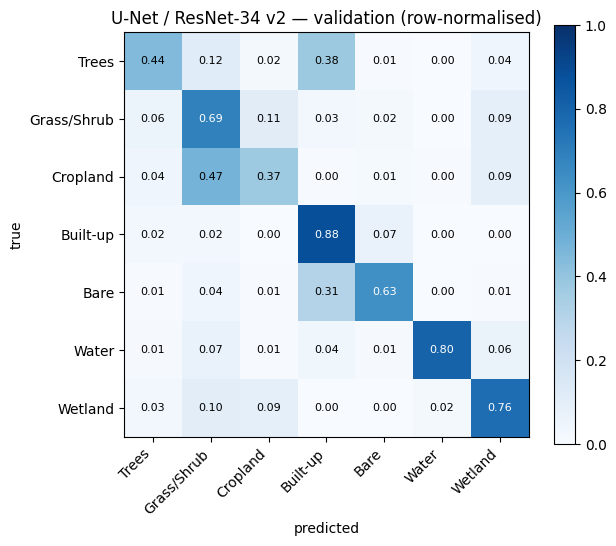

,IoU,F1
Trees,0.347,0.515
Grass/Shrub,0.489,0.656
Cropland,0.254,0.405
Built-up,0.749,0.857
Bare,0.228,0.371
Water,0.696,0.821
Wetland,0.653,0.790
mean,0.488,0.631



B_deeplab_v2  —  DeepLabV3+ / ResNet-50 v2
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
train patches 700 | val samples 1536 (128 patches x 12 months)


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

26.7 M parameters | encoder weights: imagenet | loss: CE + lovasz
step  0  loss 2.804
step 10  loss 0.790
step 20  loss 0.655
step 29  loss 0.597


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

... (115 outputs left out)

epoch 58:   0%|          | 0/43 [00:00<?, ?it/s]

ep 58 | train 0.724 | val 1.548 | OA 0.728 | mIoU 0.498 | 13s


epoch 59:   0%|          | 0/43 [00:00<?, ?it/s]

ep 59 | train 0.693 | val 1.558 | OA 0.721 | mIoU 0.494 | 13s
Done. Best val mIoU: 0.4998


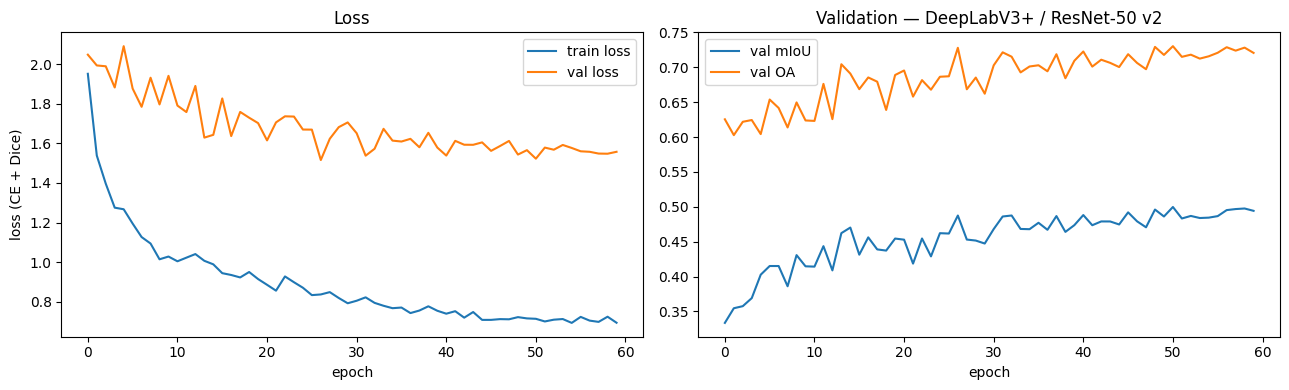

DeepLabV3+ / ResNet-50 v2: val OA 0.730 | val mIoU 0.500 | 26.7 M params | 12.4 min


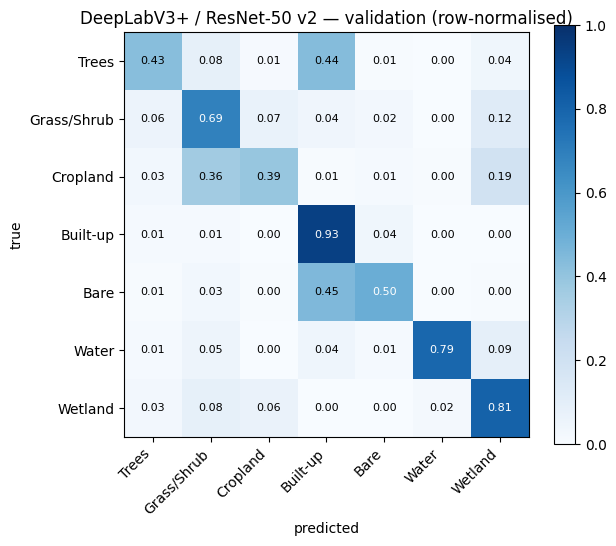

,IoU,F1
Trees,0.344,0.512
Grass/Shrub,0.527,0.690
Cropland,0.300,0.461
Built-up,0.767,0.868
Bare,0.230,0.374
Water,0.689,0.816
Wetland,0.642,0.782
mean,0.500,0.643



C_segformer_v2  —  SegFormer / MiT-B2 v2
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
train patches 700 | val samples 1536 (128 patches x 12 months)


config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

24.7 M parameters | encoder weights: imagenet | loss: CE + lovasz
step  0  loss 3.123
step 10  loss 1.082
step 20  loss 0.901
step 29  loss 0.800


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

... (79 outputs left out)

epoch 40:   0%|          | 0/43 [00:00<?, ?it/s]

ep 40 | train 0.610 | val 1.558 | OA 0.735 | mIoU 0.500 | 13s


epoch 41:   0%|          | 0/43 [00:00<?, ?it/s]

ep 41 | train 0.629 | val 1.542 | OA 0.737 | mIoU 0.497 | 12s
Early stopping.
Done. Best val mIoU: 0.5364


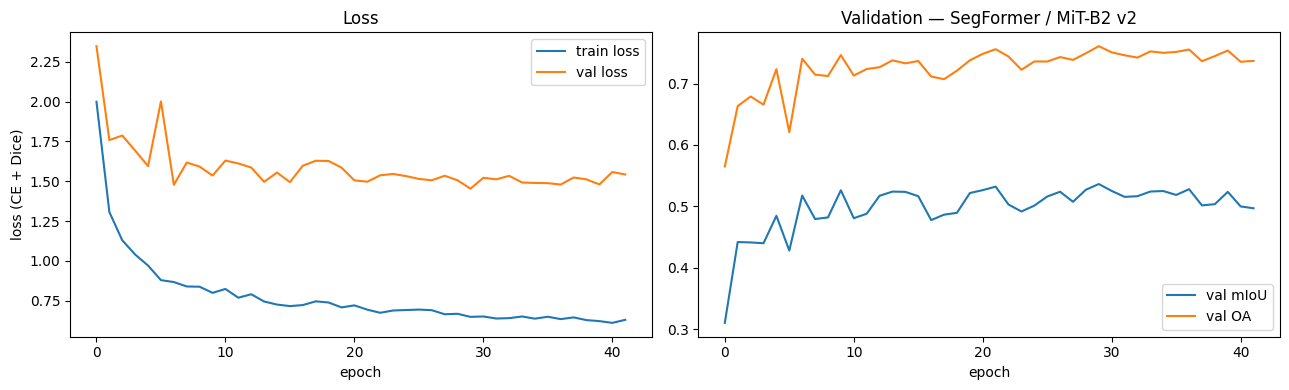

SegFormer / MiT-B2 v2: val OA 0.761 | val mIoU 0.536 | 24.7 M params | 8.8 min


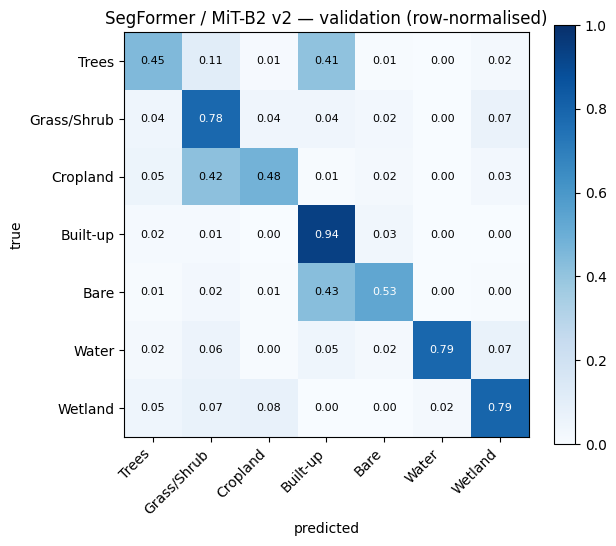

,IoU,F1
Trees,0.351,0.519
Grass/Shrub,0.589,0.742
Cropland,0.377,0.547
Built-up,0.776,0.874
Bare,0.247,0.396
Water,0.697,0.822
Wetland,0.718,0.836
mean,0.536,0.677



C_segformer_v3  —  SegFormer / MiT-B2 v3
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB
train patches 700 | val samples 1536 (128 patches x 12 months)
24.7 M parameters | encoder weights: imagenet | loss: CE + lovasz
step  0  loss 2.968
step 10  loss 1.106
step 20  loss 0.895
step 29  loss 0.819


epoch 0:   0%|          | 0/43 [00:00<?, ?it/s]

ep  0 | train 2.600 | val 2.510 | OA 0.456 | mIoU 0.198  *best* | 16s


epoch 1:   0%|          | 0/43 [00:00<?, ?it/s]

ep  1 | train 1.826 | val 2.145 | OA 0.618 | mIoU 0.348  *best* | 16s


... (88 outputs left out)

epoch 46:   0%|          | 0/43 [00:00<?, ?it/s]

ep 46 | train 0.639 | val 1.508 | OA 0.755 | mIoU 0.532 | 15s


epoch 47:   0%|          | 0/43 [00:00<?, ?it/s]

ep 47 | train 0.653 | val 1.547 | OA 0.743 | mIoU 0.520 | 15s
Early stopping.
Done. Best val mIoU: 0.5429


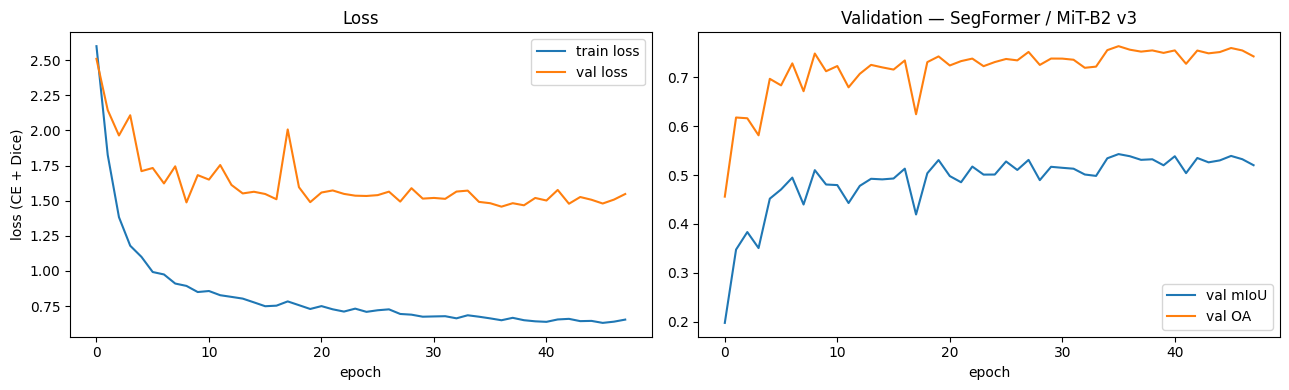

SegFormer / MiT-B2 v3: val OA 0.764 | val mIoU 0.543 | 24.7 M params | 12.3 min


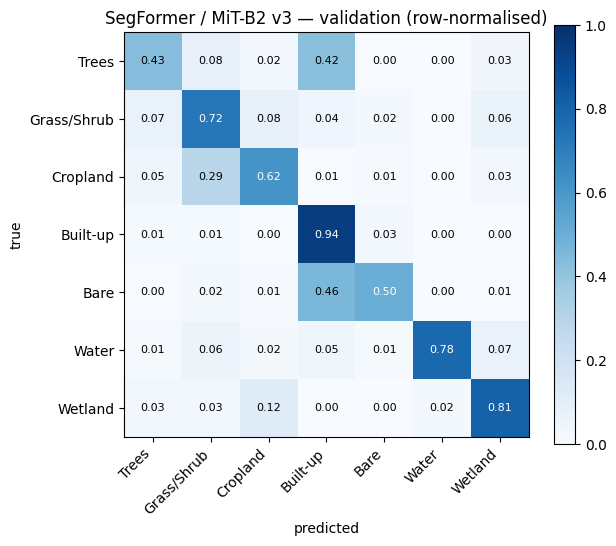

,IoU,F1
Trees,0.337,0.504
Grass/Shrub,0.593,0.744
Cropland,0.419,0.590
Built-up,0.775,0.873
Bare,0.255,0.406
Water,0.694,0.820
Wetland,0.727,0.842
mean,0.543,0.683


In [4]:
summary = []
for exp in EXPERIMENTS:
    CFG = dict(BASE, **exp)
    RUN = Path("runs") / CFG["RUN_NAME"]
    print("\n" + "=" * 90 + f"\n{CFG['RUN_NAME']}  —  {CFG['MODEL_NAME']}\n" + "=" * 90)
    if (RUN / "metrics.json").exists():
        m = json.load(open(RUN / "metrics.json"))
        print(f"already finished -> skipped (val mIoU {m['val_miou']:.3f})")
        summary.append(m); continue

    RUN, DATA, stats, index = tl.setup(CFG)
    train_dl, val_dl = tl.make_loaders(CFG, DATA, stats, index, val_ds=val_ds)
    model, CFG["WEIGHTS_USED"] = tl.build_pretrained(CFG["ARCH"], CFG["PRETRAINED"])
    json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
    model = model.to(DEV)
    loss_fn = tl.make_loss(CFG, stats)
    print(f"{tl.count_params(model):.1f} M parameters | encoder weights: {CFG['WEIGHTS_USED']} | loss: CE + {CFG['LOSS']}")
    if not (RUN / "last.pth").exists():
        tl.overfit_one_batch(model, loss_fn, train_dl, steps=30, lr=CFG["LR"] * 3)

    tl.train(model, CFG, RUN, train_dl, val_dl, loss_fn)
    tl.plot_curves(RUN, CFG["MODEL_NAME"])
    display(tl.final_validation(model, CFG, RUN, val_dl))
    summary.append(json.load(open(RUN / "metrics.json")))

    del model, train_dl; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()

## 5. Summary of this notebook's runs

In [7]:
import pandas as pd
tab = pd.DataFrame([{"run": m["run"], "val OA": m["val_oa"], "val mIoU": m["val_miou"],
                     "best epoch": m["best_epoch"], "epochs": m["epochs_run"], "min": m["train_minutes"]}
                    for m in summary]).set_index("run").sort_values("val mIoU", ascending=False)
display(tab)
print("Now run 05b_compare_r3.ipynb to compare with 04a/b/c on the same validation and test sets.")

,val OA,val mIoU,best epoch,epochs,min
run,,,,,
C_segformer_v3,0.7637,0.5429,35,48,12.3
C_segformer_v2,0.7607,0.5364,29,42,8.8
B_deeplab_v2,0.7304,0.4998,50,60,12.4
A_unet_v2,0.7077,0.4878,47,60,12.1


Now run 05b_compare_r3.ipynb to compare with 04a/b/c on the same validation and test sets.


## 6. Save results

In [ ]:
import shutil
for m in summary:
    shutil.make_archive(f"{m['run']}_results", "zip", Path("runs") / m["run"])
    print("zipped:", f"{m['run']}_results.zip")